# PowerGuard — Exploratory Data Analysis

**Цел:** Разбиране на данните от електрическата подстанция.

**Данни:** 105 000 измервания от синтетична симулация
- 100 000 нормални
- 5 000 аномалии (4 типа)

**Физика:** U = I·R, P = U·I·cos φ, P_loss = I²·R

**План:**
1. Load data
2. Първи поглед
3. Разпределения на сензорите
4. U-I диаграма
5. Feature engineering
6. Проверка на физични закони
7. Корелации
8. Изводи

In [1]:
# ═══════════════════════════════════════════════════════
# IMPORTS
# ═══════════════════════════════════════════════════════
import sys
from pathlib import Path

# Добави project root в path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.powerguard.config import SYNTHETIC_DATA_FILE, FIGURES_DIR
from src.powerguard.data.features import build_features

# Настройки
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

print("Imports OK")
print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"DATA FILE: {SYNTHETIC_DATA_FILE}")
print(f"FIGURES DIR: {FIGURES_DIR}")

Imports OK
PROJECT_ROOT: D:\CUDA\Python\ClasicML\PowerGuard
DATA FILE: D:\CUDA\Python\ClasicML\PowerGuard\data\synthetic\power_grid.parquet
FIGURES DIR: D:\CUDA\Python\ClasicML\PowerGuard\notebooks\figures


## 1. Load Data

In [2]:
# Зареждане на данни
df = pd.read_parquet(SYNTHETIC_DATA_FILE)

print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(f"\nAnomaly ratio: {df['is_anomaly'].mean():.4f}")
print(f"\nAnomaly types:")
print(df['anomaly_type'].value_counts())

Shape: (105000, 12)
Columns: ['timestamp', 'transformer_id', 'U', 'I', 'R', 'P', 'Q', 'T', 'f', 'cos_phi', 'is_anomaly', 'anomaly_type']

Anomaly ratio: 0.0476

Anomaly types:
anomaly_type
normal           100000
sensor_fault       1250
short_circuit      1250
load_loss          1250
overheat           1250
Name: count, dtype: int64


In [3]:
# Първите 10 реда
df.head(10)

,timestamp,transformer_id,U,I,R,P,Q,T,f,cos_phi,is_anomaly,anomaly_type
0,2024-01-27 23:25:00,T-1,10080.314167,91.952940,109.624707,9.057169e+05,197097.315476,22.390912,50.018842,0.977131,0,normal
1,2024-01-16 16:57:00,T-1,10593.792485,95.956928,110.401538,9.829625e+05,259141.119782,25.343554,49.977384,0.966961,0,normal
2,2024-01-11 10:07:00,T-1,9259.173156,84.533872,109.532108,7.632901e+05,173288.699390,16.580361,50.006547,0.975184,0,normal
3,2024-01-15 13:33:30,T-1,10765.832754,96.957651,111.036444,9.669665e+05,393136.897526,22.503186,49.958313,0.926364,0,normal
4,2024-01-03 21:15:30,T-1,12431.698814,113.491644,109.538450,1.363540e+06,362463.919805,31.088797,50.010637,0.966437,0,normal
5,2024-01-04 01:40:30,T-1,11543.456344,103.597997,111.425478,1.105855e+06,455203.867197,27.491227,50.005144,0.924722,0,normal
6,2024-01-24 09:31:30,T-1,11073.775288,101.321526,109.293412,1.052175e+06,389663.871209,27.681518,50.002909,0.937758,0,normal
7,2024-01-18 02:59:00,T-1,10887.783679,99.489671,109.436322,1.023955e+06,353391.939776,26.220269,49.994428,0.945286,0,normal
8,2024-01-16 10:23:00,T-1,10662.408038,97.350052,109.526475,1.005614e+06,257207.755508,24.408891,50.016194,0.968812,0,normal
9,2024-01-20 08:23:30,T-1,10874.524220,99.668769,109.106637,1.054692e+06,249711.561531,23.276587,49.996227,0.973098,0,normal


In [4]:
# Информация за колоните
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 105000 entries, 0 to 104999
Data columns (total 12 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   timestamp       105000 non-null  datetime64[us]
 1   transformer_id  105000 non-null  str           
 2   U               105000 non-null  float64       
 3   I               105000 non-null  float64       
 4   R               105000 non-null  float64       
 5   P               105000 non-null  float64       
 6   Q               105000 non-null  float64       
 7   T               105000 non-null  float64       
 8   f               105000 non-null  float64       
 9   cos_phi         105000 non-null  float64       
 10  is_anomaly      105000 non-null  int64         
 11  anomaly_type    105000 non-null  str           
dtypes: datetime64[us](1), float64(8), int64(1), str(2)
memory usage: 10.5 MB


In [5]:
# Статистики
df.describe()

,timestamp,U,I,R,P,Q,T,f,cos_phi,is_anomaly
count,105000,105000.000000,105000.000000,105000.000000,1.050000e+05,105000.000000,105000.000000,105000.000000,105000.000000,105000.000000
mean,2024-01-18 08:33:15.924285,10908.597467,104.530009,109.999487,1.061091e+06,336846.676679,26.703176,49.999872,0.949988,0.047619
min,2024-01-01 00:00:00,1382.709895,16.059992,105.625957,1.572433e+05,38675.305396,10.410506,49.903411,0.920000,0.000000
25%,2024-01-09 16:06:22.500000,10611.476051,96.574925,109.324330,9.701613e+05,281895.898296,23.083283,49.986318,0.934995,0.000000
50%,2024-01-18 08:31:45,10999.995840,100.088776,109.999330,1.044799e+06,337902.637533,25.100673,49.999842,0.949955,0.000000
75%,2024-01-27 00:39:37.500000,11387.916710,103.635841,110.673096,1.122428e+06,390334.908521,27.145437,50.013437,0.964957,0.000000
max,2024-02-04 17:19:30,14673.743453,582.194030,114.562115,3.602853e+06,851722.364246,114.994971,50.086037,0.980000,1.000000
std,NaN,1172.824133,45.168245,0.999173,2.332831e+05,78635.705950,11.348978,0.020009,0.017296,0.212960


## 2. Проверки за качество на данните

In [6]:
# Missing values
missing = df.isnull().sum()
if missing.sum() > 0:
    print("Missing values:")
    print(missing[missing > 0])
else:
    print("Няма missing values")

# Дубликати
print(f"\nDuplicate rows: {df.duplicated().sum()}")

# Timestamp range
print(f"\nTime range:")
print(f"  Start: {df['timestamp'].min()}")
print(f"  End:   {df['timestamp'].max()}")
print(f"  Duration: {df['timestamp'].max() - df['timestamp'].min()}")

# Уникални трансформатори
print(f"\nУникални transformer_id: {df['transformer_id'].unique()}")

Няма missing values

Duplicate rows: 0

Time range:
  Start: 2024-01-01 00:00:00
  End:   2024-02-04 17:19:30
  Duration: 34 days 17:19:30

Уникални transformer_id: <ArrowStringArray>
['T-1']
Length: 1, dtype: str


## 3. Разпределения на сензорите

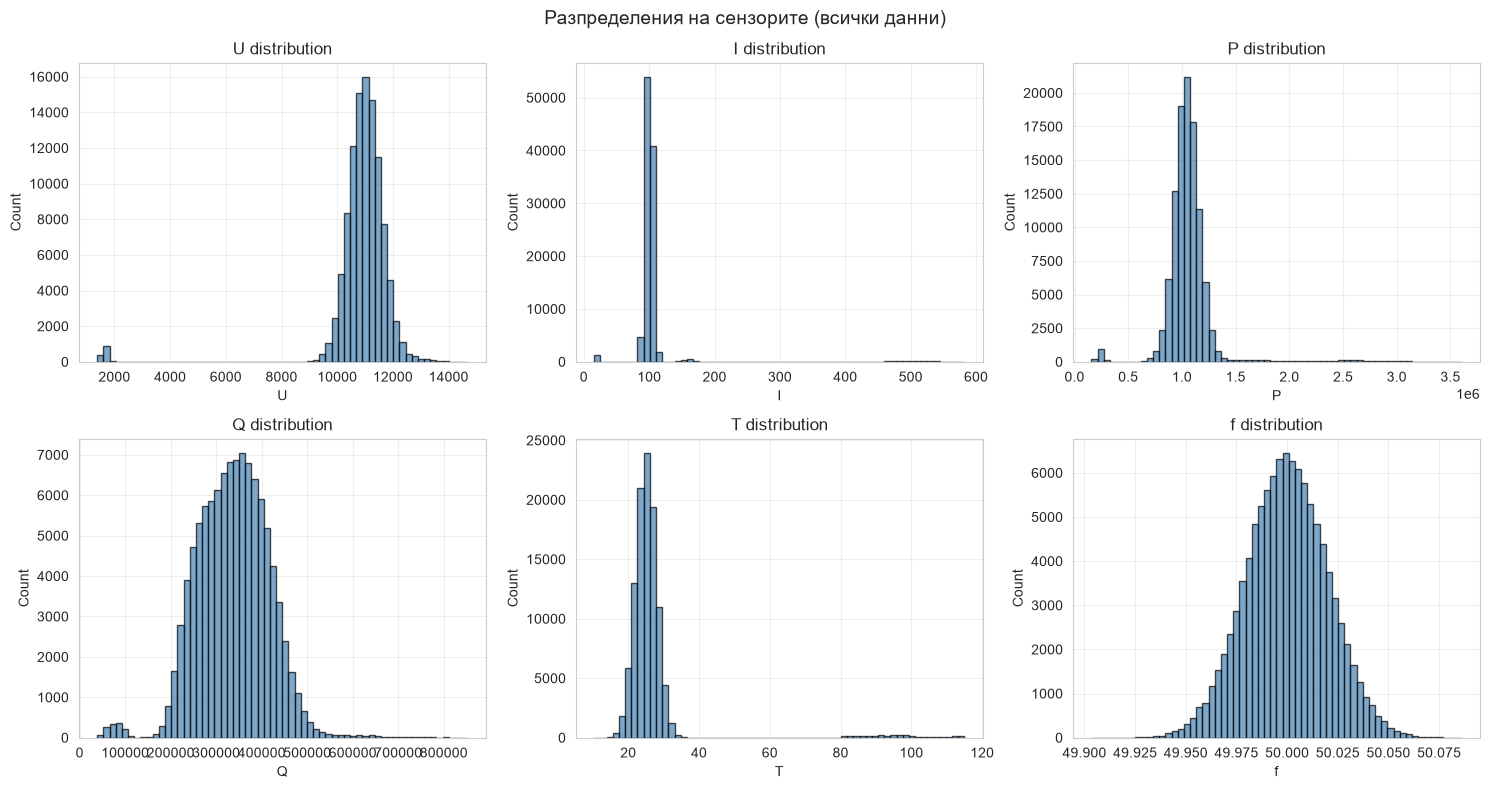

In [7]:
sensors = ["U", "I", "P", "Q", "T", "f"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), sensors):
    df[col].hist(bins=60, ax=ax, edgecolor="black", alpha=0.7, color="steelblue")
    ax.set_title(f"{col} distribution", fontsize=12)
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.grid(alpha=0.3)

plt.suptitle("Разпределения на сензорите (всички данни)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_sensor_distributions.png", dpi=100, bbox_inches="tight")
plt.show()

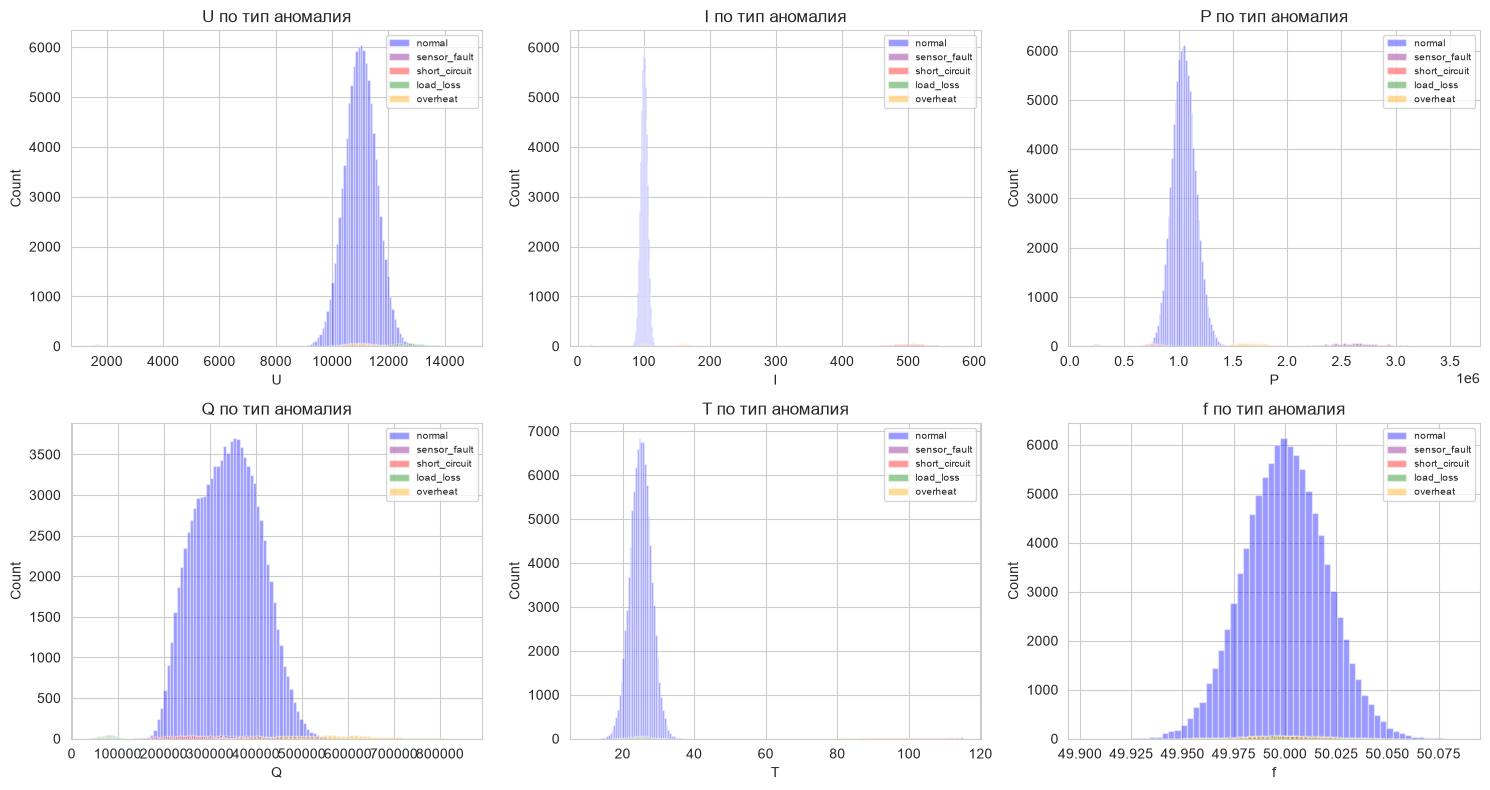

In [8]:
colors = {
    "normal": "blue",
    "overheat": "orange",
    "short_circuit": "red",
    "load_loss": "green",
    "sensor_fault": "purple",
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), sensors):
    for atype in df["anomaly_type"].unique():
        subset = df[df["anomaly_type"] == atype]
        ax.hist(subset[col], bins=60, alpha=0.4, 
                label=atype, color=colors[atype])
    ax.set_title(f"{col} по тип аномалия", fontsize=12)
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
    ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_sensor_by_anomaly.png", dpi=100, bbox_inches="tight")
plt.show()

## 4. U-I диаграма (физична проверка)

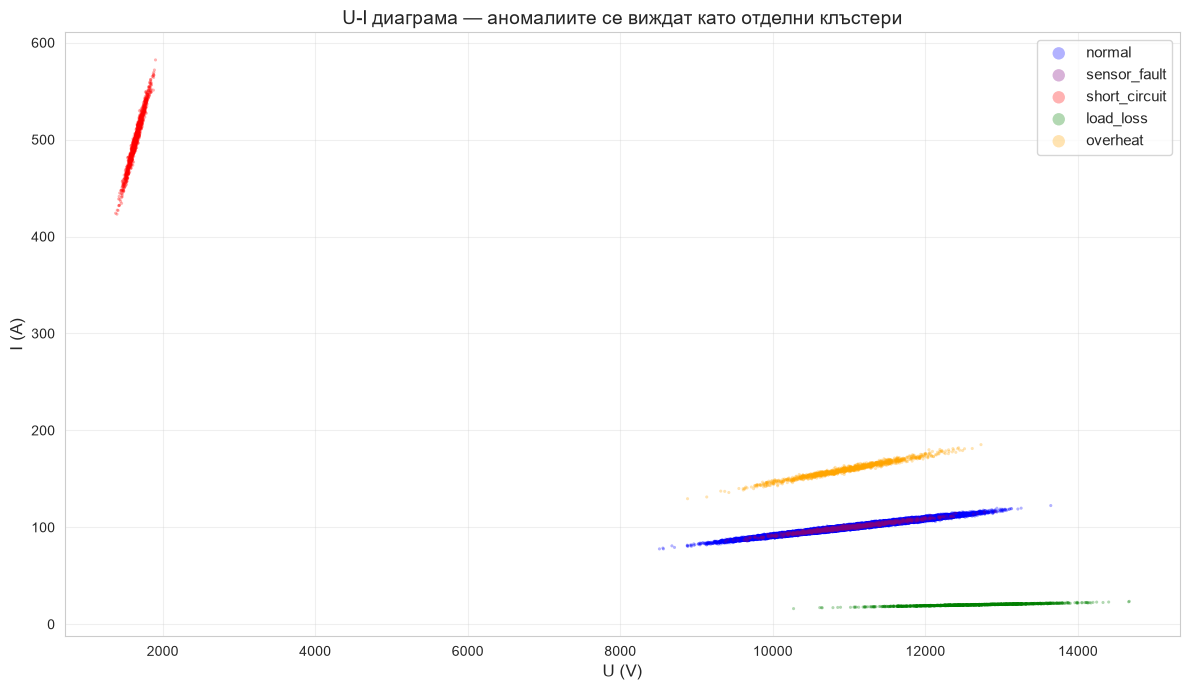

In [9]:
fig, ax = plt.subplots(figsize=(12, 7))

for atype in df["anomaly_type"].unique():
    subset = df[df["anomaly_type"] == atype]
    ax.scatter(subset["U"], subset["I"], 
               alpha=0.3, label=atype, color=colors[atype], 
               s=5, edgecolors="none")

ax.set_xlabel("U (V)", fontsize=12)
ax.set_ylabel("I (A)", fontsize=12)
ax.set_title("U-I диаграма — аномалиите се виждат като отделни клъстери", fontsize=14)
ax.legend(markerscale=4, fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_U_I_scatter.png", dpi=100, bbox_inches="tight")
plt.show()

## 5. Feature Engineering

Създаваме физично обосновани features, които кодират нарушения на физичните закони.

In [10]:
# Създай features
features = build_features(df)

print(f"Features shape: {features.shape}")
print(f"\nКолони ({len(features.columns)}):")
for i, col in enumerate(features.columns, 1):
    print(f"  {i:2d}. {col}")

Features shape: (105000, 31)

Колони (31):
   1. U
   2. I
   3. P
   4. Q
   5. T
   6. f
   7. R_calc
   8. apparent_power
   9. cos_phi_calc
  10. ohm_residual
  11. power_residual
  12. power_loss
  13. efficiency
  14. freq_deviation
  15. T_over_I
  16. T_deviation
  17. dU_dt
  18. dI_dt
  19. dP_dt
  20. dT_dt
  21. P_over_U
  22. Q_over_P
  23. I_over_U
  24. U_rolling_std_10
  25. U_rolling_mean_10
  26. I_rolling_std_10
  27. I_rolling_mean_10
  28. T_rolling_std_10
  29. T_rolling_mean_10
  30. ohm_residual_rolling_std_10
  31. ohm_residual_rolling_mean_10


In [11]:
# Средни стойности по тип аномалия
features_labeled = features.copy()
features_labeled["anomaly_type"] = df["anomaly_type"].values

key_features = ["ohm_residual", "power_residual", "power_loss", 
                "efficiency", "T_over_I", "freq_deviation"]

means = features_labeled.groupby("anomaly_type")[key_features].mean()
print("Средни стойности на ключови features по тип аномалия:")
print(means.to_string())

Средни стойности на ключови features по тип аномалия:
               ohm_residual  power_residual    power_loss  efficiency  T_over_I  freq_deviation
anomaly_type                                                                                   
load_loss      10444.347245    0.000000e+00  4.408918e+04    0.845207  1.249398        0.015475
normal             0.129721    0.000000e+00  1.102877e+06    0.487139  0.249381        0.015984
overheat       -6587.658536    0.000000e+00  2.812075e+06    0.372438  0.565664        0.015744
sensor_fault       1.356980    1.569676e+06  1.101747e+06    0.703614  0.249505        0.015576
short_circuit -53403.516135    0.000000e+00  2.760551e+07    0.027698  0.205694        0.015983


C:\Users\Krasi\AppData\Local\Temp\ipykernel_26272\1407623390.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=features_labeled, x="anomaly_type", y=col,
C:\Users\Krasi\AppData\Local\Temp\ipykernel_26272\1407623390.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=features_labeled, x="anomaly_type", y=col,
C:\Users\Krasi\AppData\Local\Temp\ipykernel_26272\1407623390.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=features_labeled, x="anomaly_type", y=col,
C:\Users\Krasi\AppData\Local\Temp\ipykernel_26272\1407623390.py:

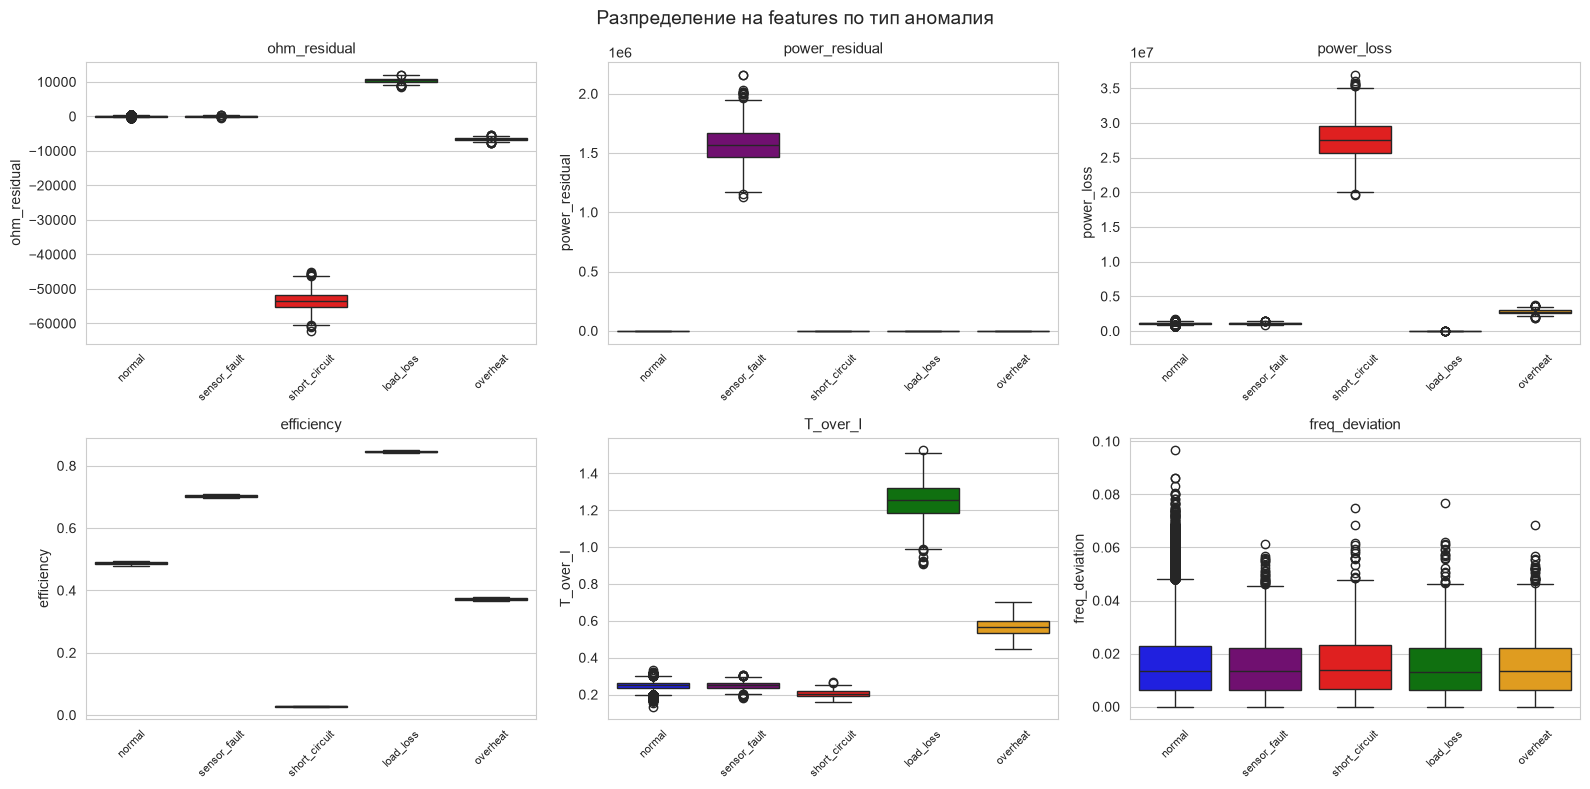

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

plot_features = ["ohm_residual", "power_residual", "power_loss", 
                 "efficiency", "T_over_I", "freq_deviation"]

for ax, col in zip(axes.flatten(), plot_features):
    sns.boxplot(data=features_labeled, x="anomaly_type", y=col, 
                ax=ax, palette=colors)
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45, labelsize=8)

plt.suptitle("Разпределение на features по тип аномалия", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_features_boxplots.png", dpi=100, bbox_inches="tight")
plt.show()

## 6. Проверка на физични закони

In [13]:
print("═" * 60)
print("ЗАКОН НА ОМ: U = I·R")
print("═" * 60)

normal = df[df["anomaly_type"] == "normal"]
ohm_normal = (normal["U"] - normal["I"] * normal["R"]).abs()

print(f"\nНормални данни:")
print(f"  Mean |residual|: {ohm_normal.mean():.4f} V")
print(f"  Max |residual|:  {ohm_normal.max():.4f} V")
print(f"  Relative error:  {ohm_normal.mean() / normal['U'].mean() * 100:.6f}%")

print(f"\nАномалии — нарушения на закона:")
for atype in ["load_loss", "overheat", "short_circuit", "sensor_fault"]:
    subset = df[df["anomaly_type"] == atype]
    residual = (subset["U"] - subset["I"] * subset["R"]).abs().mean()
    print(f"  {atype:15s}: {residual:>12.2f} V")

════════════════════════════════════════════════════════════
ЗАКОН НА ОМ: U = I·R
════════════════════════════════════════════════════════════

Нормални данни:
  Mean |residual|: 0.0000 V
  Max |residual|:  0.0000 V
  Relative error:  0.000000%

Аномалии — нарушения на закона:
  load_loss      :     10445.37 V
  overheat       :      6587.11 V
  short_circuit  :     53363.30 V
  sensor_fault   :         0.00 V


In [14]:
print("═" * 60)
print("МОЩНОСТЕН БАЛАНС: P = U·I·cos φ")
print("═" * 60)

normal = df[df["anomaly_type"] == "normal"]
power_normal = (normal["P"] - normal["U"] * normal["I"] * normal["cos_phi"]).abs()

print(f"\nНормални данни: {power_normal.mean():.4f} W")

print(f"\nАномалии — нарушения на баланса:")
for atype in ["load_loss", "overheat", "short_circuit", "sensor_fault"]:
    subset = df[df["anomaly_type"] == atype]
    residual = (subset["P"] - subset["U"] * subset["I"] * subset["cos_phi"]).abs().mean()
    print(f"  {atype:15s}: {residual:>15.2f} W")

════════════════════════════════════════════════════════════
МОЩНОСТЕН БАЛАНС: P = U·I·cos φ
════════════════════════════════════════════════════════════

Нормални данни: 0.0000 W

Аномалии — нарушения на баланса:
  load_loss      :            0.00 W
  overheat       :            0.00 W
  short_circuit  :            0.00 W
  sensor_fault   :      1569675.97 W


In [15]:
print("═" * 60)
print("ДЖАУЛОВИ ЗАГУБИ: P_loss = I²·R")
print("═" * 60)

print(f"\nСредни загуби по тип:")
for atype in df["anomaly_type"].unique():
    subset = df[df["anomaly_type"] == atype]
    loss = (subset["I"]**2 * subset["R"]).mean()
    print(f"  {atype:15s}: {loss:>15.2f} W")

════════════════════════════════════════════════════════════
ДЖАУЛОВИ ЗАГУБИ: P_loss = I²·R
════════════════════════════════════════════════════════════

Средни загуби по тип:
  normal         :      1102877.36 W
  sensor_fault   :      1101747.03 W
  short_circuit  :     27605511.47 W
  load_loss      :        44089.18 W
  overheat       :      2812074.85 W


## 7. Time Series (първите 2000 измервания)

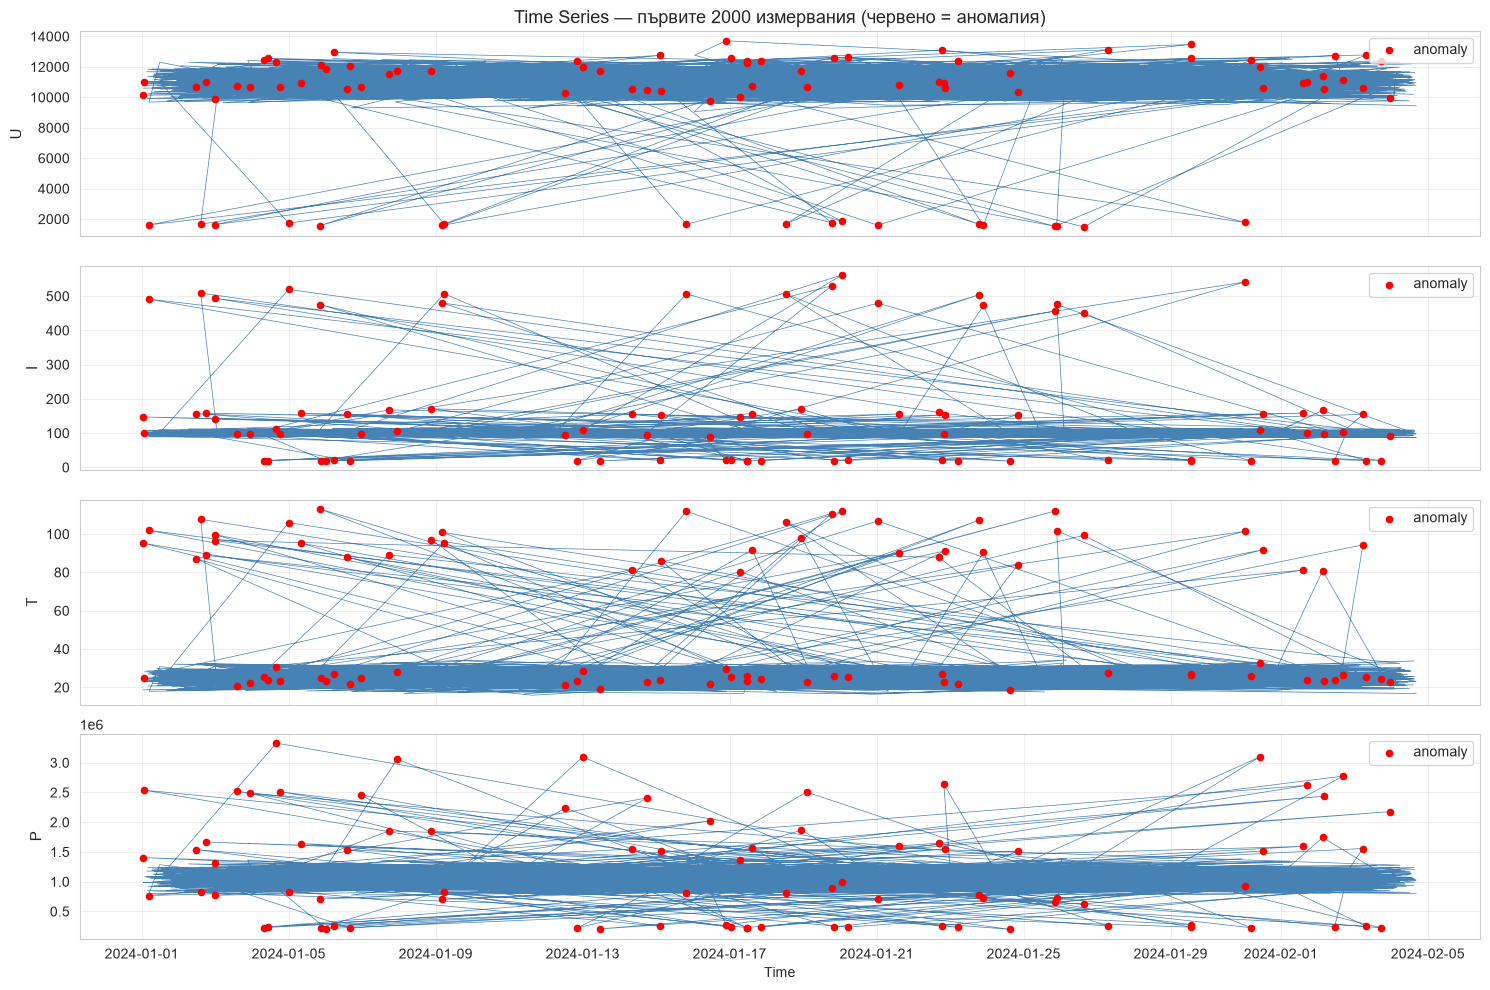

In [16]:
n = 2000
subset = df.iloc[:n]

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

for ax, col in zip(axes, ["U", "I", "T", "P"]):
    ax.plot(subset["timestamp"], subset[col], linewidth=0.5, color="steelblue")
    
    # Маркирай аномалиите
    anomalies = subset[subset["is_anomaly"] == 1]
    if len(anomalies) > 0:
        ax.scatter(anomalies["timestamp"], anomalies[col], 
                   color="red", s=20, zorder=5, label="anomaly")
    
    ax.set_ylabel(col, fontsize=11)
    ax.legend(loc="upper right")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Time")
axes[0].set_title("Time Series — първите 2000 измервания (червено = аномалия)", fontsize=13)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_time_series.png", dpi=100, bbox_inches="tight")
plt.show()

## 8. Корелации

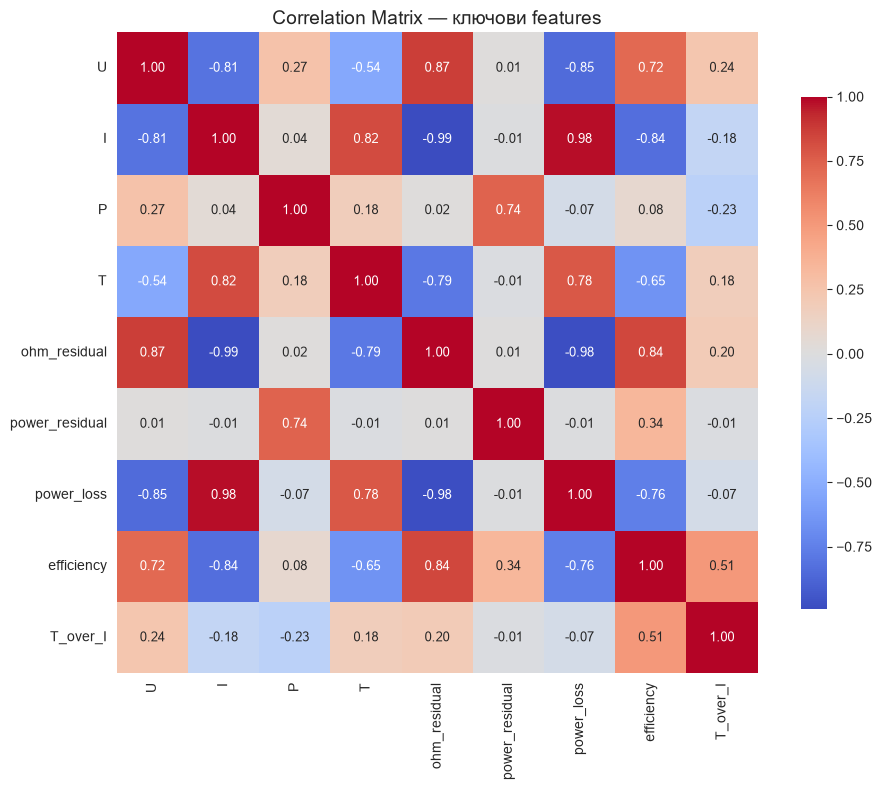

In [17]:
corr_features = ["U", "I", "P", "T", 
                 "ohm_residual", "power_residual", 
                 "power_loss", "efficiency", "T_over_I"]

corr = features[corr_features].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, ax=ax, cbar_kws={"shrink": 0.8},
            annot_kws={"fontsize": 9})
ax.set_title("Correlation Matrix — ключови features", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_correlations.png", dpi=100, bbox_inches="tight")
plt.show()

## 9. Изводи

### Данни
- **105 000 измервания** (100 000 нормални + 5 000 аномалии)
- **4 типа аномалии** — по 1250 всеки
- **Anomaly ratio: 4.76%** — imbalanced dataset

### Разпределения
- Нормални: U ≈ 11 000 V, I ≈ 100 A, T ≈ 25°C, f ≈ 50 Hz
- Всички сензори имат **bimodal** разпределения

### Физични проверки
- **Закон на Ом**: нормални ≈ 0 V, аномалии (без sensor_fault) → голям residual
- **Мощностен баланс**: нормални ≈ 0 W, **само sensor_fault** има голям residual
- Всеки тип аномалия нарушава различен физичен закон

### Уникални подписи на аномалиите

| Аномалия | Уникален признак | Feature |
|----------|------------------|---------|
| **load_loss** | I ↓ (×0.2), U ↑ (×1.15) | `T_over_I` ↑↑ |
| **overheat** | I ↑ (×1.6), T ↑ (90°C) | `power_loss` ×2.5, `T_over_I` ↑ |
| **short_circuit** | U ↓ (×0.15), I ↑↑ (×5) | `efficiency` → 0.03, `power_loss` ×25 |
| **sensor_fault** | P ≠ U·I·cos φ | **`power_residual` ≠ 0** |

### Заключения за ML

1. **Feature engineering е критичен** — features като `power_residual` хващат аномалии, които суровите сензори не могат
2. **Класовете са разделими** — всеки тип има уникален подпис
3. **Imbalanced data** — ще използваме AUC-PR вместо accuracy
4. **Physics-informed ML** — features кодират физични закони

### Следващи стъпки
- **02_classifier.ipynb** — 6 класификатора (LR, DT, RF, SVM, XGBoost, LightGBM)
- **03_anomaly.ipynb** — 4 anomaly detector-а (IF, OCSVM, LOF, Autoencoder)
- **04_fusion.ipynb** — ensemble на моделите